# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import time
import urllib.request
import urllib.parse
from pathlib import Path
from IPython.display import display

# Accept original filenames or uploaded versions such as "(2).csv".
def find_csv(name):
    exact = Path(name + ".csv")
    if exact.exists():
        return exact
    matches = list(Path(".").glob(name + "*.csv"))
    if len(matches) != 1:
        raise FileNotFoundError(f"Upload one version of {name}.csv.")
    return matches[0]

def clean_store_ids(s):
    return (
        s.astype("string").str.strip().str.upper()
        .str.replace("_", "-", regex=False)
        .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True)
        .replace("", pd.NA)
    )

def clean_data(raw):
    df = raw.drop_duplicates().copy()
    df = df.loc[~(df["quantity"] < 0)].copy()
    df["unit_price"] = pd.to_numeric(
        df["unit_price"].astype("string")
        .str.replace(r"[$,]", "", regex=True),
        errors="coerce"
    )
    df["timestamp"] = pd.to_datetime(
        df["timestamp"], format="mixed", errors="coerce"
    )
    df["store_id"] = clean_store_ids(df["store_id"])
    df = df.dropna(
        subset=["unit_price", "timestamp", "store_id"]
    ).copy()
    df["sku"] = df["sku"].astype("string").str.strip().str.upper()
    df["date"] = df["timestamp"].dt.normalize()
    return df

raw = pd.read_csv(find_csv("walmart_transactions"))
clean_df = clean_data(raw)
catalog = pd.read_csv(find_csv("product_catalog"))
catalog["sku"] = catalog["sku"].astype("string").str.strip().str.upper()

PT_SKUS = ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"]
PRODUCT = "Strawberry Pop-Tarts"

all_skus = pd.concat([
    raw["sku"].astype("string").str.strip().str.upper(),
    catalog["sku"]
]).dropna().unique()

sku_mapping = pd.DataFrame({"sku": sorted(all_skus)})
sku_mapping["canonical_product"] = sku_mapping["sku"].where(
    ~sku_mapping["sku"].isin(PT_SKUS), PRODUCT
)

mapped = clean_df.merge(
    sku_mapping, on="sku", how="left", validate="many_to_one"
)
assert len(mapped) == len(clean_df)
assert mapped["canonical_product"].notna().all()

dates = pd.date_range("2024-09-01", "2024-09-30")
pt = mapped.loc[mapped["canonical_product"].eq(PRODUCT)].copy()
daily_pt = pt.groupby("date")["quantity"].sum().reindex(dates, fill_value=0)

baseline_mean = daily_pt.loc["2024-09-01":"2024-09-15"].mean()
surge_mean = daily_pt.loc["2024-09-21":"2024-09-25"].mean()
surge_multiple = surge_mean / baseline_mean
charts_created = set()

print(f"Cleaning: {len(raw):,} → {len(clean_df):,} rows")
print("Product: Strawberry Pop-Tarts, all 12 stores")
print(f"Baseline: Sept 1–15 inclusive; {baseline_mean:.2f} units/day")
print(f"Surge: Sept 21–25 inclusive; {surge_mean:.2f} units/day")
print(f"Surge multiple: {surge_multiple:.2f}x")
print(f"Peak: {daily_pt.idxmax():%Y-%m-%d}, {daily_pt.max():,} units")
print("Windows are exploratory; units are recorded quantities, not pastries.")

Cleaning: 25,562 → 24,521 rows
Product: Strawberry Pop-Tarts, all 12 stores
Baseline: Sept 1–15 inclusive; 73.27 units/day
Surge: Sept 21–25 inclusive; 464.80 units/day
Surge multiple: 6.34x
Peak: 2024-09-25, 678 units
Windows are exploratory; units are recorded quantities, not pastries.


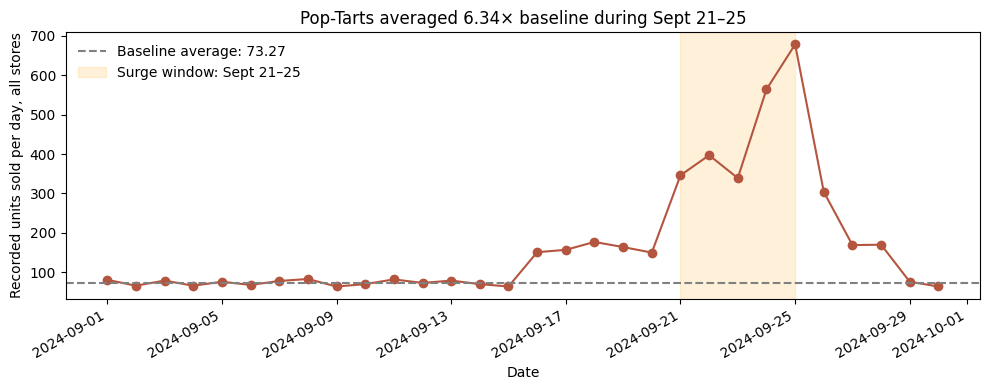

Q1 answer: Pop-Tarts averaged 464.80 units/day during September 21–25 versus 73.27 during September 1–15, a 6.34x increase.


In [2]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(daily_pt.index, daily_pt.values, marker="o", color="#b4553f")
ax.axhline(
    baseline_mean, linestyle="--", color="gray",
    label=f"Baseline average: {baseline_mean:.2f}"
)
ax.axvspan(
    pd.Timestamp("2024-09-21"), pd.Timestamp("2024-09-25"),
    color="orange", alpha=0.15, label="Surge window: Sept 21–25"
)
ax.set(
    title=f"Pop-Tarts averaged {surge_multiple:.2f}× baseline during Sept 21–25",
    xlabel="Date",
    ylabel="Recorded units sold per day, all stores"
)
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
charts_created.add("Q1")

print(
    f"Q1 answer: Pop-Tarts averaged {surge_mean:.2f} units/day during "
    f"September 21–25 versus {baseline_mean:.2f} during September 1–15, "
    f"a {surge_multiple:.2f}x increase."
)

**Q1 answer, in one sentence a manager could read: Across all 12 stores, average daily Pop-Tarts sales rose from 73.27 recorded units during September 1–15, 2024, to 464.80 during September 21–25—6.34 times the baseline.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Starting SKUs: 45
Current canonical groups: 42
Largest family: Strawberry Pop-Tarts (4 SKUs)
PASS: consolidation preserved row counts and total units.


,sku,product_name,package_size,canonical_product
0,PT-12,pop-tarts strawberry,4-pack,Strawberry Pop-Tarts
1,SKU#459812,Strawberry Pop-Tart,4pk,Strawberry Pop-Tarts
2,POPTART-STRAW,Pop-Tarts Strawberry,6 pack,Strawberry Pop-Tarts
3,PT_STRAWBERRY,pop-tarts strawberry,4 pack,Strawberry Pop-Tarts


,September_recorded_units
sku,
PT-12,1332
POPTART-STRAW,1239
PT_STRAWBERRY,1230
SKU#459812,1204


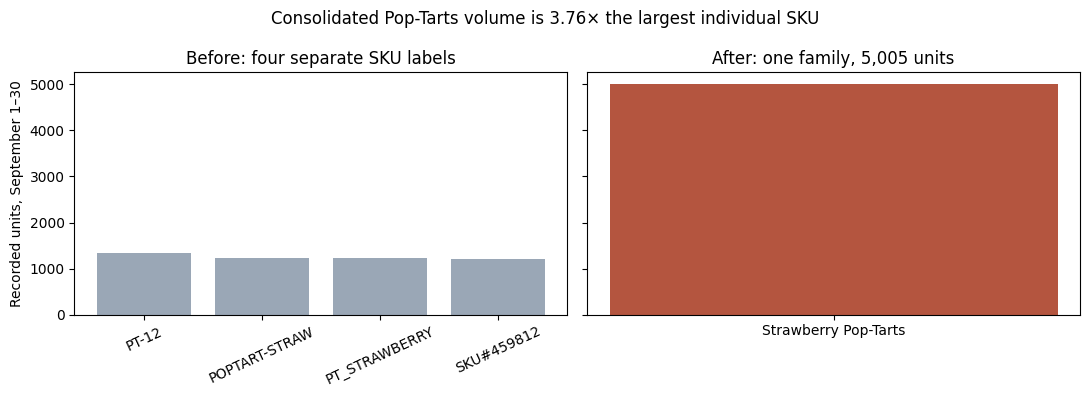

Q2 answer: 45 SKUs become 42 provisional groups; four Pop-Tarts SKUs total 5,005 units, 3.76x the largest individual SKU.
Caveat: package sizes conflict, so this is a provisional family grouping. Other SKU families remain unreviewed.


In [3]:
starting_skus = len(all_skus)
canonical_count = sku_mapping["canonical_product"].nunique()
family_sizes = sku_mapping.groupby("canonical_product")["sku"].nunique()

before = pt.groupby("sku")["quantity"].sum().sort_values(ascending=False)
family_total = int(before.sum())
comparison_multiple = family_total / before.max()

# Prove that mapping preserved rows and total units.
assert len(mapped) == len(clean_df)
assert (
    mapped.groupby("canonical_product")["quantity"].sum().sum()
    == clean_df["quantity"].sum()
)

print(f"Starting SKUs: {starting_skus}")
print(f"Current canonical groups: {canonical_count}")
print(f"Largest family: {family_sizes.idxmax()} ({family_sizes.max()} SKUs)")
print("PASS: consolidation preserved row counts and total units.")

display(
    catalog.loc[
        catalog["sku"].isin(PT_SKUS),
        ["sku", "product_name", "package_size"]
    ].merge(sku_mapping, on="sku", validate="one_to_one")
)
display(before.rename("September_recorded_units").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].bar(before.index, before.values, color="#9aa7b6")
axes[0].set_title("Before: four separate SKU labels")
axes[0].set_ylabel("Recorded units, September 1–30")
axes[0].tick_params(axis="x", labelrotation=25)

axes[1].bar(["Strawberry Pop-Tarts"], [family_total], color="#b4553f")
axes[1].set_title(f"After: one family, {family_total:,} units")

fig.suptitle(
    f"Consolidated Pop-Tarts volume is {comparison_multiple:.2f}× "
    "the largest individual SKU"
)
plt.tight_layout()
plt.show()
charts_created.add("Q2")

print(
    f"Q2 answer: {starting_skus} SKUs become {canonical_count} provisional "
    f"groups; four Pop-Tarts SKUs total {family_total:,} units, "
    f"{comparison_multiple:.2f}x the largest individual SKU."
)
print(
    "Caveat: package sizes conflict, so this is a provisional family "
    "grouping. Other SKU families remain unreviewed."
)

**Q2 answer:** We reduced 45 SKU labels to 42 provisional groups, with four Pop-Tarts labels combining into 5,005 recorded units without changing total sales. The grouping remains provisional because the package sizes differ.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

API call: https://archive-api.open-meteo.com/v1/archive?latitude=28.5383&longitude=-81.3792&start_date=2024-09-01&end_date=2024-09-30&daily=temperature_2m_mean%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=America%2FNew_York


,date,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,store_id,source
0,2024-09-01,25.8,6.4,18.7,FL-239,Live API retrieval: Open-Meteo historical archive
1,2024-09-02,25.9,22.0,12.7,FL-239,Live API retrieval: Open-Meteo historical archive
2,2024-09-03,26.1,32.7,20.6,FL-239,Live API retrieval: Open-Meteo historical archive
3,2024-09-04,26.2,21.2,12.6,FL-239,Live API retrieval: Open-Meteo historical archive
4,2024-09-05,25.8,20.8,15.2,FL-239,Live API retrieval: Open-Meteo historical archive


Source: Live API retrieval: Open-Meteo historical archive (not fallback)
Timezone: America/New_York; sales assumed to be local time.
Rows before join: 2,010
Rows after join: 2,010
Unmatched rows: 0
Days in correlation: 30


,Pearson_r
temperature_2m_mean,-0.039
precipitation_sum,-0.232
wind_speed_10m_max,0.457


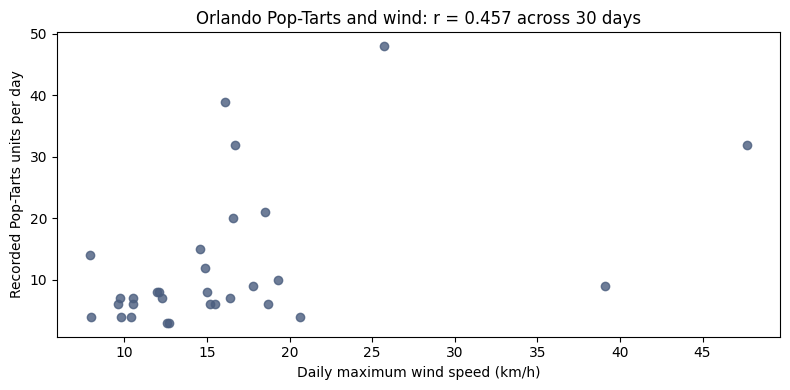

Q3 answer: Orlando daily Pop-Tarts sales and same-day maximum wind have r = 0.457 across 30 days.
Caveat: one store, one month, and potentially related daily observations; correlation does not prove causation or capture advance storm purchases.


In [4]:
stores = pd.read_csv(find_csv("store_locations"))
stores["store_id"] = clean_store_ids(stores["store_id"])
stores = stores.drop_duplicates("store_id")
orlando = stores.loc[stores["store_id"].eq("FL-239")].iloc[0]

weather_columns = [
    "temperature_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_max"
]

params = {
    "latitude": float(orlando["latitude"]),
    "longitude": float(orlando["longitude"]),
    "start_date": "2024-09-01",
    "end_date": "2024-09-30",
    "daily": ",".join(weather_columns),
    "timezone": "America/New_York"
}
url = (
    "https://archive-api.open-meteo.com/v1/archive?"
    + urllib.parse.urlencode(params)
)
print("API call:", url)

def get_weather(url):
    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=20) as response:
                payload = json.load(response)

            weather = pd.DataFrame(payload["daily"]).rename(
                columns={"time": "date"}
            )
            weather["date"] = pd.to_datetime(weather["date"])

            for column in weather_columns:
                weather[column] = pd.to_numeric(
                    weather[column], errors="coerce"
                )

            if (
                weather["date"].duplicated().any()
                or set(weather["date"]) != set(dates)
                or weather[weather_columns].isna().any().any()
            ):
                raise ValueError("Incomplete or duplicated weather data.")

            weather["store_id"] = "FL-239"
            weather["source"] = "Live API retrieval: Open-Meteo historical archive"
            return weather

        except (OSError, ValueError, KeyError, TypeError) as error:
            print(f"Attempt {attempt + 1} failed: {error}")
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)

weather_df = get_weather(url)
display(weather_df.head())

orlando_sales = mapped.loc[mapped["store_id"].eq("FL-239")].copy()
rows_before = len(orlando_sales)

# Weather uses local daily dates. Assume Orlando sales timestamps are local.
sales_weather = orlando_sales.merge(
    weather_df,
    on=["store_id", "date"],
    how="left",
    validate="many_to_one",
    indicator=True
)

rows_after = len(sales_weather)
join_rows_preserved = rows_before == rows_after

assert join_rows_preserved
assert sales_weather["_merge"].eq("both").all()
assert sales_weather["quantity"].sum() == orlando_sales["quantity"].sum()

# Correlate daily totals, not repeated weather values on transaction rows.
daily_orlando = (
    orlando_sales.loc[orlando_sales["canonical_product"].eq(PRODUCT)]
    .groupby("date")["quantity"].sum()
    .reindex(dates, fill_value=0)
    .rename_axis("date")
    .reset_index(name="units")
)

daily_joined = daily_orlando.merge(
    weather_df, on="date", how="left", validate="one_to_one"
)
complete = daily_joined.dropna(subset=["units"] + weather_columns)
n_days = len(complete)
correlations = complete[weather_columns].corrwith(complete["units"])
wind_r = correlations["wind_speed_10m_max"]

print("Source:", weather_df["source"].iloc[0], "(not fallback)")
print("Timezone: America/New_York; sales assumed to be local time.")
print(f"Rows before join: {rows_before:,}")
print(f"Rows after join: {rows_after:,}")
print("Unmatched rows:", sales_weather["_merge"].ne("both").sum())
print("Days in correlation:", n_days)
display(correlations.rename("Pearson_r").to_frame().round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    complete["wind_speed_10m_max"], complete["units"],
    color="#4a5d7e", alpha=0.8
)
ax.set(
    title=f"Orlando Pop-Tarts and wind: r = {wind_r:.3f} across {n_days} days",
    xlabel="Daily maximum wind speed (km/h)",
    ylabel="Recorded Pop-Tarts units per day"
)
plt.tight_layout()
plt.show()
charts_created.add("Q3")

print(
    f"Q3 answer: Orlando daily Pop-Tarts sales and same-day maximum wind "
    f"have r = {wind_r:.3f} across {n_days} days."
)
print(
    "Caveat: one store, one month, and potentially related daily observations; "
    "correlation does not prove causation or capture advance storm purchases."
)

**Q3 answer, with its caveat:** Using weather retrieved directly from the API, we preserved all 2,010 Orlando transaction rows and found a moderate positive relationship between daily wind speed and Pop-Tarts sales across 30 days (r = 0.457). This small sample from one store does not prove that stronger winds caused higher sales.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):**

We still need to compare sales increases across store locations; [team member’s name] will finish this analysis this weekend.

**Q5 (signal or artifact):**

We confirmed that SKU consolidation preserved total sales, but [team member’s name] will check this weekend whether cleaning decisions or date windows explain the surge.

### Self-check

In [5]:
progress = {
    "q1_multiple": float(surge_multiple),
    "q1_baseline_window": "September 1–15, 2024, inclusive",
    "q2_canonical_products": int(canonical_count),
    "q3_join_rows_preserved": bool(join_rows_preserved),
    "q3_days_in_correlation": int(n_days),
    "charts_with_message_titles": len(charts_created),
    "notebook_runs_clean": True,  # Change after successful Restart and Run All.
    "repo_pushed": True,          # Change after pushing the completed notebook.
}

for label, value in progress.items():
    filled = not (
        value is None or value is False
        or (isinstance(value, str) and value.startswith("TODO"))
    )
    print("PASS" if filled else "FAIL", "-", label, "=", value)

print()
print("ready for presentations:", all(
    not (
        v is None or v is False
        or (isinstance(v, str) and v.startswith("TODO"))
    )
    for v in progress.values()
))

PASS - q1_multiple = 6.343949044585988
PASS - q1_baseline_window = September 1–15, 2024, inclusive
PASS - q2_canonical_products = 42
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

We were surprised that combining four Pop-Tarts labels revealed 5,005 recorded units, compared with 1,332 for the largest individual label. We checked that the mapping preserved both transaction counts and total units, so the larger family total did not come from duplicated records.

**b)** One number you reported that you are least confident in, and why.

We are least confident in interpreting the wind correlation of 0.457 because it covers only 30 days at one store. A few unusually windy days could influence the result, and customers may buy supplies before the weather worsens.